# Treasury Cash Forecasting with N-HiTS / TFT

A treasury that cannot predict its cash needs has to hold a bigger buffer, borrow at short notice, or both. The size of the forecast error is therefore a direct input to the liquidity buffer. This notebook forecasts the U.S. Treasury's own daily cash flows, the cleanest public example of the problem, with two modern deep-learning models and the classical benchmarks.

**What it does.** It forecasts the U.S. Treasury's daily operating cash flows (deposits and withdrawals, excluding debt issuance and redemptions) 20 business days ahead, the problem every treasury cash-management desk solves to size its liquidity buffer.

Two deep-learning forecasters (N-HiTS and the Temporal Fusion Transformer) are compared with seasonal-naive, ETS and ARIMA benchmarks in a rolling-origin backtest. Results are shown for daily flows and for the cumulative cash-balance path.

**Data.** The Daily Treasury Statement from the U.S. Treasury Fiscal Data API: every line of Table II (deposits and withdrawals of operating cash) since 2015.

**Methods.** ETL of about 340,000 DTS lines into daily totals with DuckDB, and a calendar feature set (tax dates, benefit-payment days, month ends, holidays).

The forecasters are `statsforecast` (SeasonalNaive, AutoETS, AutoARIMA) and `neuralforecast` (NHITS, and TFT with future calendar covariates), compared over 8 rolling 20-day windows.

**Key output.** Error by model and horizon for daily flows and for the 20-day cumulative balance change, the calendar effects the models learn, and a forecast dashboard.

## 1. Why cash forecasting is a risk function

A treasury that cannot predict its cash needs must hold a larger buffer, issue at short notice, or both. The U.S. Treasury itself is the cleanest public example. Its operating cash, the Treasury General Account at the Fed, moves by tens of billions of dollars a day as taxes come in and benefits, salaries and contracts go out. Debt issuance is then planned around the forecast.

The same problem appears at any MDB or corporate treasury: forecast net operating flows, add a margin for forecast error, and the result is the liquidity buffer. The **size of the forecast error** is therefore a direct input to the buffer, which makes forecast accuracy a risk metric rather than an academic one.

Debt cash issues and redemptions are excluded from the target. They are Treasury's own financing decisions, made *in response* to the forecast, so including them would forecast policy rather than flows.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import torch

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import duckdb
import logging
import neuralforecast
import statsforecast
from neuralforecast import NeuralForecast
from neuralforecast.losses.pytorch import MAE as NF_MAE
from neuralforecast.models import NHITS, TFT
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA, AutoETS, SeasonalNaive

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

DTS_START = "2015-01-01"
H = 20  # forecast horizon, business days
N_WINDOWS = 8  # rolling-origin windows, each H days apart
# history window of the neural models (≈ 6 months)
INPUT_SIZE = 120
MAX_STEPS = 800
# attention model: fewer, smaller steps keep it to a few minutes on a laptop
# CPU
TFT_STEPS = 300
# business days of history for the statistical models (≈ 3 years)
STAT_HISTORY = 750
SEED = 7
torch.manual_seed(SEED)
torch.set_num_threads(max(1, (os.cpu_count() or 4) // 2))
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
os.environ["NIXTLA_ID_AS_COL"] = "1"

print(
    f"neuralforecast {neuralforecast.__version__} · statsforecast"
    f" {statsforecast.__version__} · run on {dt.date.today():%Y-%m-%d}"
)

neuralforecast 3.3.0 · statsforecast 2.0.1 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


MODEL_COLORS = {
    "SeasonalNaive": "#9c9b97",
    "AutoETS": PALETTE[3],
    "AutoARIMA": PALETTE[0],
    "NHITS": PALETTE[2],
    "TFT": PALETTE[1],
}

## 3. ETL: the Daily Treasury Statement

Table II of the DTS lists every category of deposit and withdrawal each business day. The API is paged (10,000 lines per call). Daily totals are built in DuckDB, excluding public-debt cash issues and redemptions and any inter-account transfers or subtotal lines. The account changed name in 2021 (Federal Reserve Account → Treasury General Account); both are included.

In [3]:
DTS_URL = "https://api.fiscaldata.treasury.gov/services/api/fiscal_service/v1/accounting/dts/deposits_withdrawals_operating_cash"


def fetch_dts():
    rows, page = [], 1
    fields = "record_date,account_type,transaction_type,transaction_catg,transaction_today_amt"
    while True:
        r = requests.get(
            DTS_URL,
            params={
                "filter": f"record_date:gte:{DTS_START}",
                "fields": fields,
                "page[size]": 10_000,
                "page[number]": page,
                "sort": "record_date",
            },
            timeout=120,
        )
        r.raise_for_status()
        js = r.json()
        rows += js["data"]
        if page >= js["meta"]["total-pages"]:
            break
        page += 1
    return pd.DataFrame(rows)


t0 = time.perf_counter()
dts = cached("dts_table2", fetch_dts, max_age_hours=24)
dts["amount"] = pd.to_numeric(dts["transaction_today_amt"], errors="coerce")
con = duckdb.connect()
con.register("dts", dts)
daily = con.sql("""
    SELECT CAST(record_date AS DATE) AS ds,
           SUM(amount) FILTER (WHERE transaction_type = 'Deposits') / 1000.0    AS deposits,
           SUM(amount) FILTER (WHERE transaction_type = 'Withdrawals') / 1000.0 AS withdrawals
    FROM dts
    WHERE (account_type ILIKE '%Federal Reserve Account%' OR account_type ILIKE '%Treasury General Account%')
      AND transaction_catg NOT ILIKE '%Public Debt%'
      AND transaction_catg NOT ILIKE '%Total%'
      AND transaction_catg NOT ILIKE '%Sub-total%'
      AND transaction_catg NOT ILIKE '%Transfer%'
    GROUP BY 1 ORDER BY 1
""").df()
daily["ds"] = pd.to_datetime(daily["ds"])
daily["net"] = daily["deposits"] - daily["withdrawals"]
print(
    f"{len(dts):,} DTS lines → {len(daily):,} business days"
    f" {daily['ds'].min():%Y-%m-%d} → {daily['ds'].max():%Y-%m-%d} in"
    f" {time.perf_counter() - t0:.0f}s ($bn)"
)
daily.set_index("ds")[["deposits", "withdrawals", "net"]].describe().T[
    ["mean", "std", "min", "max"]
].round(1)

339,190 DTS lines → 2,962 business days 2015-01-02 → 2026-10-16 in 1s ($bn)


,mean,std,min,max
deposits,69.80,103.20,-1.00,734.70
withdrawals,75.30,104.50,-26.60,633.70
net,-5.50,40.60,-272.20,407.50


## 4. Calendar features

Most of the predictable variation in government cash is calendar-driven:

- **mid-month tax dates** (the 15th and the business day after), and the April, June, September and January estimated-tax months;
- **benefit-payment days**: Social Security pays on the 3rd and on the second, third and fourth Wednesdays; Supplemental Security Income on the 1st;
- **month ends and month starts** (salaries, Medicare and Medicaid, interest);
- the **day of the week** and days next to federal holidays.

These are known in advance, so they enter the neural models as *future* covariates, and they explain much of why a naive forecast fails.

In [4]:
def calendar_features(dates):
    d = pd.DatetimeIndex(dates)
    bdays = pd.bdate_range(
        d.min() - pd.Timedelta(days=40), d.max() + pd.Timedelta(days=40)
    )
    f = pd.DataFrame(index=d)
    f["dow"] = d.dayofweek / 4.0
    f["dom"] = (d.day - 1) / 30.0
    f["mid_month_tax"] = ((d.day >= 15) & (d.day <= 18)).astype(float)
    f["tax_month"] = (
        d.month.isin([1, 4, 6, 9]).astype(float) * f["mid_month_tax"]
    )
    f["april_15"] = ((d.month == 4) & (d.day >= 15) & (d.day <= 19)).astype(
        float
    )
    nth_wed = ((d.day - 1) // 7 + 1) * (d.dayofweek == 2)
    f["ss_wednesday"] = np.isin(nth_wed, [2, 3, 4]).astype(float)
    f["first_3_days"] = (d.day <= 3).astype(float)
    month_end = pd.Series(d, index=d).groupby([d.year, d.month]).transform(
        "max"
    ) == pd.Series(d, index=d)
    f["month_end"] = month_end.astype(float).to_numpy()
    first_bd = pd.Series(d, index=d).groupby([d.year, d.month]).transform(
        "min"
    ) == pd.Series(d, index=d)
    f["first_bday"] = first_bd.astype(float).to_numpy()
    gap_before = pd.Series(d).diff().dt.days.fillna(1).to_numpy()
    f["after_holiday"] = (
        (gap_before > 1) & (d.dayofweek != 0) | (gap_before > 3)
    ).astype(float)
    return f.reset_index(drop=True)


FEATS = [
    "dow",
    "dom",
    "mid_month_tax",
    "tax_month",
    "april_15",
    "ss_wednesday",
    "first_3_days",
    "month_end",
    "first_bday",
    "after_holiday",
]
long = pd.concat(
    [
        daily[["ds", "deposits"]]
        .rename(columns={"deposits": "y"})
        .assign(unique_id="deposits"),
        daily[["ds", "withdrawals"]]
        .rename(columns={"withdrawals": "y"})
        .assign(unique_id="withdrawals"),
    ],
    ignore_index=True,
)
long = long.sort_values(["unique_id", "ds"]).reset_index(drop=True)
cal = calendar_features(daily["ds"]).assign(ds=daily["ds"].to_numpy())
long = long.merge(cal, on="ds", how="left")
# Business-day index: the models see a regular series of trading days
long["ds_real"] = long["ds"]
long["ds"] = long.groupby("unique_id").cumcount()

# Average calendar effects (in $bn), as a first look
eff = pd.DataFrame(
    {
        f: [
            daily.loc[cal[f].to_numpy() == 1, c].mean()
            - daily.loc[cal[f].to_numpy() == 0, c].mean()
            for c in ["deposits", "withdrawals"]
        ]
        for f in [
            "mid_month_tax",
            "april_15",
            "ss_wednesday",
            "first_3_days",
            "month_end",
            "first_bday",
        ]
    },
    index=["deposits", "withdrawals"],
).T
eff.round(1)

,deposits,withdrawals
mid_month_tax,34.10,16.00
april_15,85.70,15.70
ss_wednesday,-41.90,-14.80
first_3_days,11.70,49.50
month_end,53.70,65.80
first_bday,37.20,91.50


## 5. Models and the rolling-origin backtest

Both series (deposits and withdrawals) are forecast jointly; the **net flow** is their difference. The backtest uses the last 8 windows of 20 business days (about eight months). Each model forecasts 20 days ahead from each origin without seeing the window.

| Model | Notes |
|---|---|
| **SeasonalNaive** | the same business day one month (21 days) earlier |
| **AutoETS**, **AutoARIMA** | `statsforecast`, season length 21 (about a business month) |
| **N-HiTS** (Challu et al., 2023) | hierarchical interpolation MLP over multiple frequencies; 120-day input, calendar covariates for the forecast days |
| **TFT** (Lim et al., 2021) | attention-based, with gating and variable selection; same inputs |

Neural models are trained once on the data before the first window (`refit=False`) with an MAE loss. Flows are in $bn per day.

In [5]:
Y = long[["unique_id", "ds", "y"] + FEATS]
t0 = time.perf_counter()
sf = StatsForecast(
    models=[
        SeasonalNaive(season_length=21),
        AutoETS(season_length=21),
        AutoARIMA(season_length=21, max_p=3, max_q=3),
    ],
    freq=1,
    n_jobs=1,
)
# The statistical models only need recent history; ~3 years per series keeps
# AutoARIMA's seasonal search tractable
Y_stat = (
    Y[["unique_id", "ds", "y"]]
    .groupby("unique_id")
    .tail(STAT_HISTORY + H * N_WINDOWS)
)
cv_stat = sf.cross_validation(df=Y_stat, h=H, n_windows=N_WINDOWS, step_size=H)
t_stat = time.perf_counter() - t0

t0 = time.perf_counter()
models = [
    NHITS(
        h=H,
        input_size=INPUT_SIZE,
        futr_exog_list=FEATS,
        max_steps=MAX_STEPS,
        learning_rate=1e-3,
        scaler_type="robust",
        loss=NF_MAE(),
        random_seed=SEED,
        enable_progress_bar=False,
        enable_model_summary=False,
        logger=False,
    ),
    TFT(
        h=H,
        input_size=INPUT_SIZE,
        futr_exog_list=FEATS,
        hidden_size=32,
        max_steps=TFT_STEPS,
        learning_rate=1e-3,
        # TFT is far heavier than NHITS on a CPU
        windows_batch_size=128,
        scaler_type="robust",
        loss=NF_MAE(),
        random_seed=SEED,
        enable_progress_bar=False,
        enable_model_summary=False,
        logger=False,
    ),
]
nf = NeuralForecast(models=models, freq=1)
cv_nn = nf.cross_validation(
    df=Y, n_windows=N_WINDOWS, step_size=H, refit=False
)
t_nn = time.perf_counter() - t0
cv = cv_stat.merge(
    cv_nn[["unique_id", "ds", "cutoff", "NHITS", "TFT"]],
    on=["unique_id", "ds", "cutoff"],
)
MODELS = list(MODEL_COLORS)
print(
    f"statsforecast CV {t_stat:.0f}s · neuralforecast CV {t_nn:.0f}s ·"
    f" {cv['cutoff'].nunique()} windows × {H} days × 2 series"
)

# Net flow and cumulative 20-day balance change, per window
wide = cv.pivot_table(
    index=["cutoff", "ds"], columns="unique_id", values=["y"] + MODELS
)
net = pd.DataFrame({
    k: wide[(k, "deposits")] - wide[(k, "withdrawals")] for k in ["y"] + MODELS
})
net["h"] = net.groupby(level="cutoff").cumcount() + 1
cum = net.groupby(level="cutoff")[["y"] + MODELS].cumsum()
cum["h"] = net["h"]


def scores(frame, cols):
    return pd.DataFrame({
        m: {
            "MAE": (frame[m] - frame["y"]).abs().mean(),
            "RMSE": np.sqrt(((frame[m] - frame["y"]) ** 2).mean()),
        }
        for m in cols
    }).T


tab = pd.concat(
    {
        "deposits (daily)": scores(cv[cv["unique_id"] == "deposits"], MODELS),
        "withdrawals (daily)": scores(
            cv[cv["unique_id"] == "withdrawals"], MODELS
        ),
        "net flow (daily)": scores(net, MODELS),
        "cumulative net, day 20": scores(cum[cum["h"] == H], MODELS),
    },
    axis=1,
)
tab["skill vs SeasonalNaive (net daily MAE)"] = (
    1
    - tab[("net flow (daily)", "MAE")]
    / tab.loc["SeasonalNaive", ("net flow (daily)", "MAE")]
)
tab.round(2)

Seed set to 7


Seed set to 7


statsforecast CV 518s · neuralforecast CV 484s · 8 windows × 20 days × 2 series


deposits (daily)        withdrawals (daily)         \
                           MAE   RMSE                 MAE   RMSE   
SeasonalNaive           174.02 214.84              170.16 205.99   
AutoETS                 131.31 142.92              134.34 149.06   
AutoARIMA               129.36 144.83              133.55 150.20   
NHITS                   107.95 137.53              115.68 146.98   
TFT                      45.09  72.59               52.72  89.25   

              net flow (daily)       cumulative net, day 20         \
                           MAE  RMSE                    MAE   RMSE   
SeasonalNaive            73.41 96.82                 353.56 406.21   
AutoETS                  51.39 73.59                 363.47 477.01   
AutoARIMA                57.76 78.53                 359.82 485.60   
NHITS                    58.22 76.90                 481.32 564.59   
TFT                      42.12 65.70                 269.49 334.79   

              skill vs SeasonalNaive (net daily MAE)  
                                                      
SeasonalNaive                                   0.00  
AutoETS                                         0.30  
AutoARIMA                                       0.21  
NHITS                                           0.21  
TFT                                             0.43

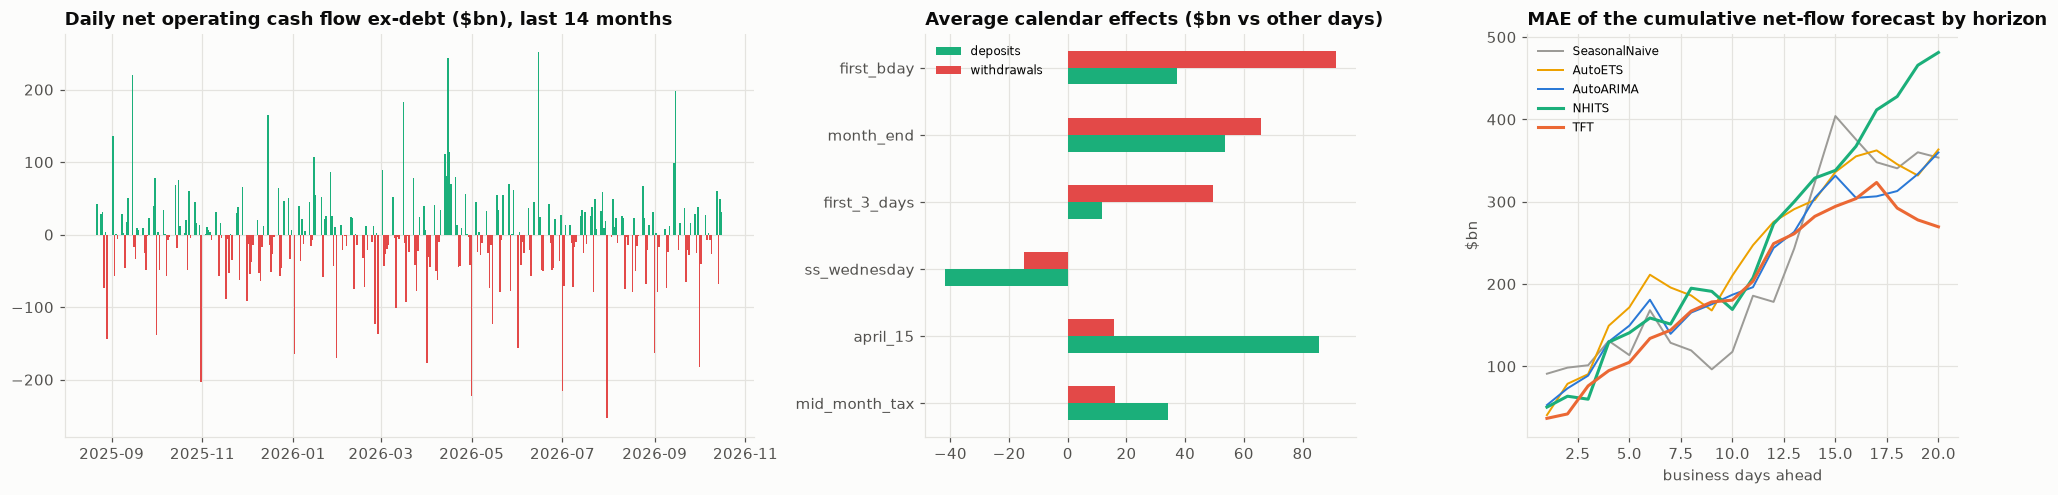

In [6]:
# --- Chart 1: history, calendar effects and error by horizon
fig, axes = plt.subplots(
    1, 3, figsize=(18, 4.6), gridspec_kw={"width_ratios": [1.6, 1, 1]}
)
ax = axes[0]
recent = daily[daily["ds"] >= daily["ds"].max() - pd.Timedelta(days=420)]
ax.bar(
    recent["ds"],
    recent["net"],
    width=1.0,
    color=np.where(recent["net"] >= 0, PALETTE[2], PALETTE[7]),
)
ax.set_title("Daily net operating cash flow ex-debt ($bn), last 14 months")
ax = axes[1]
eff.plot.barh(ax=ax, color=[PALETTE[2], PALETTE[7]])
ax.set_title("Average calendar effects ($bn vs other days)")
ax.legend(fontsize=8)
ax = axes[2]
for mname, col in MODEL_COLORS.items():
    e = (cum[mname] - cum["y"]).abs().groupby(cum["h"]).mean()
    ax.plot(
        e.index,
        e.values,
        color=col,
        lw=2 if mname in ("NHITS", "TFT") else 1.3,
        label=mname,
    )
ax.set_xlabel("business days ahead")
ax.set_ylabel("$bn")
ax.set_title("MAE of the cumulative net-flow forecast by horizon")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_flows_calendar_horizon")
plt.show()

## 6. From forecast error to a liquidity buffer

If the treasury holds a buffer to cover the forecast error of cumulative flows with 95% confidence, the buffer scales with the error distribution. The 95th percentile of the absolute 20-day cumulative error is the buffer each model implies, a direct translation of forecast skill into dollars.

In [7]:
buffer = pd.Series(
    {m: np.quantile((cum[m] - cum["y"]).abs(), 0.95) for m in MODELS},
    name="95% buffer for 1–20 day cumulative error ($bn)",
)
best = tab[("cumulative net, day 20", "MAE")].idxmin()
saving = buffer["SeasonalNaive"] - buffer[best]
print(
    f"Best 20-day cumulative forecast: {best} · buffer ${buffer[best]:.0f}bn"
    f" vs ${buffer['SeasonalNaive']:.0f}bn for seasonal naive (${saving:.0f}bn"
    " smaller)"
)
buffer.round(1).to_frame()

Best 20-day cumulative forecast: TFT · buffer $477bn vs $492bn for seasonal naive ($15bn smaller)


,95% buffer for 1–20 day cumulative error ($bn)
SeasonalNaive,492.40
AutoETS,699.70
AutoARIMA,638.90
NHITS,642.40
TFT,476.90


## 7. Results dashboard

In [8]:
last_cut = cv["cutoff"].max()
lw = net.xs(last_cut, level="cutoff")
lc = cum.xs(last_cut, level="cutoff")
dates_last = long.loc[
    (long["unique_id"] == "deposits") & long["ds"].isin(lw.index),
    ["ds", "ds_real"],
].set_index("ds")["ds_real"]
dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.16,
    horizontal_spacing=0.09,
    subplot_titles=(
        "Last window: daily net flow, actual vs forecasts ($bn)",
        "Last window: cumulative net flow ($bn)",
        "MAE by model ($bn): daily net vs 20-day cumulative",
        "95% liquidity buffer implied by forecast error ($bn)",
    ),
)
xd = dates_last.reindex(lw.index).to_numpy()
dash.add_trace(
    go.Bar(x=xd, y=lw["y"], name="actual", marker_color="#c9c8c3"), 1, 1
)
for mname, col in MODEL_COLORS.items():
    dash.add_trace(
        go.Scatter(
            x=xd,
            y=lw[mname],
            name=mname,
            line=dict(
                color=col, width=2 if mname in ("NHITS", "TFT") else 1.2
            ),
        ),
        1,
        1,
    )
    dash.add_trace(
        go.Scatter(
            x=xd,
            y=lc[mname],
            name=mname,
            showlegend=False,
            line=dict(
                color=col, width=2 if mname in ("NHITS", "TFT") else 1.2
            ),
        ),
        1,
        2,
    )
dash.add_trace(
    go.Scatter(
        x=xd,
        y=lc["y"],
        name="actual cumulative",
        line=dict(color=INK, width=3),
    ),
    1,
    2,
)
dash.add_trace(
    go.Bar(
        x=MODELS,
        y=tab[("net flow (daily)", "MAE")],
        name="daily net MAE",
        marker_color=PALETTE[0],
    ),
    2,
    1,
)
dash.add_trace(
    go.Bar(
        x=MODELS,
        y=tab[("cumulative net, day 20", "MAE")],
        name="20-day cumulative MAE",
        marker_color=PALETTE[3],
    ),
    2,
    1,
)
dash.add_trace(
    go.Bar(
        x=MODELS,
        y=buffer,
        marker_color=[MODEL_COLORS[m] for m in MODELS],
        showlegend=False,
        text=buffer.round(0),
        textposition="outside",
    ),
    2,
    2,
)
dash.update_layout(
    height=950,
    width=1400,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font=dict(color=INK_2),
    barmode="group",
    legend=dict(orientation="h", y=-0.08),
    margin=dict(t=130),
    title=dict(
        x=0.01,
        text=(
            "<b>U.S. Treasury operating cash forecasting ·"
            f" {N_WINDOWS} rolling 20-day windows to"
            f" {daily['ds'].max():%d %b %Y}</b><br><span"
            f" style='font-size:13px;color:{INK_2}'>Daily Treasury Statement,"
            f" flows ex-debt · best 20-day cumulative: {best} (MAE"
            f" ${tab.loc[best, ('cumulative net, day 20', 'MAE')]:.0f}bn) ·"
            f" buffer ${buffer[best]:.0f}bn vs"
            f" ${buffer['SeasonalNaive']:.0f}bn seasonal naive</span>"
        ),
    ),
)
save_dashboard(dash, "dashboard")
tab.to_csv(OUT_DIR / "forecast_scores.csv")
buffer.to_csv(OUT_DIR / "liquidity_buffer.csv")
cv.to_csv(OUT_DIR / "cv_forecasts.csv", index=False)
daily.to_csv(OUT_DIR / "dts_daily_flows.csv", index=False)
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 8. Reading the results and limitations

Daily Treasury Statement, 2,962 business days (January 2015 – October 2026), backtest on the last 8 windows of 20 days:

**The calendar is most of the signal.** Raw averages already show it: on mid-month tax days deposits are $34bn higher than on other days (and $86bn higher on 15 April). On the first business day of the month withdrawals are $92bn higher (benefits, interest, salaries). Social Security Wednesdays, month ends and the first three days of the month all move flows by tens of billions.

**TFT is clearly the best daily forecaster.** For gross deposits and withdrawals its MAE is $45bn and $53bn, against $108–116bn for N-HiTS, about $130bn for ETS and ARIMA and $170bn for seasonal naive. For the daily **net** flow its MAE is $42bn, 43% better than seasonal naive.

TFT uses the known future calendar through its variable-selection and attention layers, which lets it place tax dates and payment days exactly. The statistical models only see a 21-day seasonality, which drifts against a calendar that varies from month to month.

**N-HiTS gets the gross flows right but the net wrong.** Its gross errors are lower than ARIMA's, but its 20-day cumulative net error ($481bn MAE) is the worst of all. Small biases of the same sign in deposits and withdrawals do not cancel, and they accumulate over 20 days. A model has to be judged on the quantity the treasury manages (the balance path), not only on daily accuracy.

**What it is worth.** A buffer that covers the 1–20-day cumulative forecast error with 95% confidence is **$477bn** with TFT, against $492bn for seasonal naive and $640–700bn for N-HiTS, ARIMA and ETS. Even the best model leaves a large residual: the 20-day cumulative net is hard to forecast because of lumpy items (corporate tax payments, large one-off disbursements) that the calendar cannot anticipate.

- **For an MDB treasury** the lessons transfer directly: model the known calendar of loan disbursements, repayments and bond coupons explicitly, evaluate on the cumulative cash path, and size the buffer from the empirical error distribution rather than from a normal approximation.

**Limitations**

- Eight 20-day windows (about eight months) is a short backtest; errors in a year with a debt-ceiling episode or a pandemic would be far larger.
- Debt issuance and redemptions are excluded by design: they are decisions, not forecasts. The operating-cash flows still include items with policy discretion.
- Hyper-parameters are fixed (input window 120 days, 800 N-HiTS steps, 300 TFT steps); TFT was trained with a reduced budget to keep the notebook to about 20 minutes on a CPU.

## References

### Finance and regulation

- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.). OTexts. https://otexts.com/fpp3/
- Hyndman, R. J., & Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting, 22*(4), 679–688. https://doi.org/10.1016/j.ijforecast.2006.03.001
- Basel Committee on Banking Supervision. (2008). *Principles for sound liquidity risk management and supervision*. Bank for International Settlements. https://www.bis.org/publ/bcbs144.htm

### Machine learning and deep learning

- Challu, C., Olivares, K. G., Oreshkin, B. N., Garza Ramirez, F., Mergenthaler Canseco, M., & Dubrawski, A. (2023). NHITS: Neural hierarchical interpolation for time series forecasting. In *Proceedings of the AAAI Conference on Artificial Intelligence, 37*(6), 6989–6997. https://doi.org/10.1609/aaai.v37i6.25854
- Lim, B., Arık, S. Ö., Loeff, N., & Pfister, T. (2021). Temporal fusion transformers for interpretable multi-horizon time series forecasting. *International Journal of Forecasting, 37*(4), 1748–1764. https://doi.org/10.1016/j.ijforecast.2021.03.012
- Oreshkin, B. N., Carpov, D., Chapados, N., & Bengio, Y. (2020). N-BEATS: Neural basis expansion analysis for interpretable time series forecasting. In *Proceedings of the 8th International Conference on Learning Representations*. https://arxiv.org/abs/1905.10437
- Hyndman, R. J., & Khandakar, Y. (2008). Automatic time series forecasting: The forecast package for R. *Journal of Statistical Software, 27*(3), 1–22. https://doi.org/10.18637/jss.v027.i03